In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Upload dataset
uploaded = files.upload()

# Get uploaded file name automatically
file_name = next(iter(uploaded))

# Load dataset
df = pd.read_csv(file_name)

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Display shape
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

Saving recommendation_system_dataset_25_rows (2).csv to recommendation_system_dataset_25_rows (2) (1).csv
First 5 rows of the dataset:


,User_ID,Item,Genre,Rating,Watch_Time,Genre_Match,Previous_Interaction,Like
0,U01,Inception,Sci-Fi,4.8,High,1,1,1
1,U02,The Dark Knight,Action,4.7,High,1,1,1
2,U03,Finding Nemo,Animation,4.2,High,1,1,1
3,U04,The Notebook,Romance,2.4,Low,0,0,0
4,U05,Interstellar,Sci-Fi,4.9,High,1,1,1



Dataset Shape: (25, 8)

Column Names:
['User_ID', 'Item', 'Genre', 'Rating', 'Watch_Time', 'Genre_Match', 'Previous_Interaction', 'Like']


In [ ]:

# Step 4: Data Preprocessing

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate records if any
df = df.drop_duplicates()

print("\nDataset Shape After Cleaning:", df.shape)

print("\nLike / Not Like Distribution:")
print(df["Like"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   User_ID               25 non-null     object 
 1   Item                  25 non-null     object 
 2   Genre                 25 non-null     object 
 3   Rating                25 non-null     float64
 4   Watch_Time            25 non-null     object 
 5   Genre_Match           25 non-null     int64  
 6   Previous_Interaction  25 non-null     int64  
 7   Like                  25 non-null     int64  
dtypes: float64(1), int64(3), object(4)
memory usage: 1.7+ KB

Missing Values:
User_ID                 0
Item                    0
Genre                   0
Rating                  0
Watch_Time              0
Genre_Match             0
Previous_Interaction    0
Like                    0
dtype: int64

Duplicate Rows: 0

Dataset Shape After Cleaning: (25, 8)

Like / N

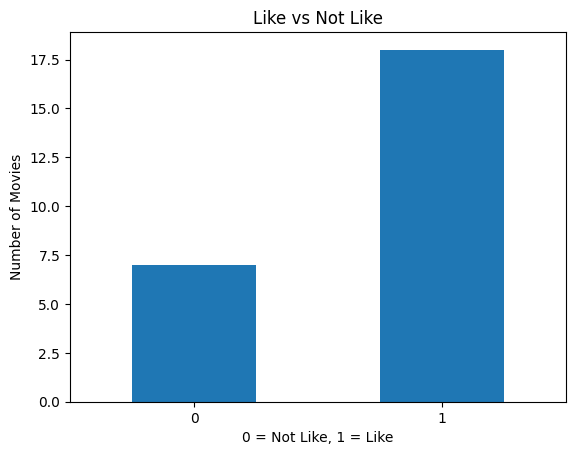

Average Rating by Genre:
Genre
Sci-Fi       4.625000
Animation    4.500000
Action       4.450000
Adventure    3.900000
Drama        3.800000
Romance      3.375000
Thriller     3.350000
Comedy       3.233333
Horror       2.833333
Name: Rating, dtype: float64


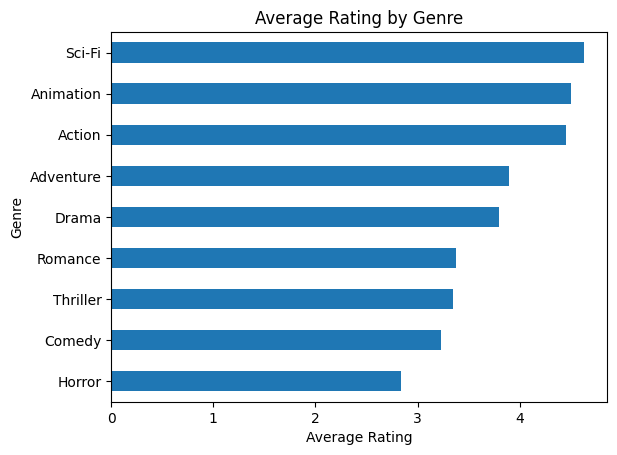

In [ ]:

import matplotlib.pyplot as plt

# Count likes and dislikes
df["Like"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.title("Like vs Not Like")
plt.xlabel("0 = Not Like, 1 = Like")
plt.ylabel("Number of Movies")
plt.show()

# Average rating by genre
genre_rating = df.groupby("Genre")["Rating"].mean()

print("Average Rating by Genre:")
print(genre_rating.sort_values(ascending=False))

genre_rating.sort_values().plot(kind="barh")
plt.title("Average Rating by Genre")
plt.xlabel("Average Rating")
plt.show()

In [ ]:

# Step 6: Train Logistic Regression Model

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Select input features
X = df[[
    "Genre",
    "Rating",
    "Watch_Time",
    "Genre_Match",
    "Previous_Interaction"
]]

# Target column
y = df["Like"]

# Convert categorical columns into numerical features
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         ["Genre", "Watch_Time"])
    ],
    remainder="passthrough"
)

# Split dataset into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create and train model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Display results
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))
print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Training Records: 20
Testing Records: 5
Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         1
           1       1.00      1.00      1.00         4

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5


Confusion Matrix:
[[1 0]
 [0 4]]


In [ ]:

# Step 7: Generate Movie Recommendations

# Copy dataset so original data remains unchanged
recommendations = df.copy()

# Calculate probability of the user liking each movie
recommendations["Like_Probability"] = model.predict_proba(
    X
)[:, 1]

# Predict Like (1) or Not Like (0)
recommendations["Predicted_Like"] = model.predict(X)

# Keep movies predicted as Like
recommended_movies = recommendations[
    recommendations["Predicted_Like"] == 1
].copy()

# Sort by highest Like probability
recommended_movies = recommended_movies.sort_values(
    by="Like_Probability",
    ascending=False
)

# Display top 10 recommendations
print("TOP MOVIE RECOMMENDATIONS")
display(
    recommended_movies[
        ["Item", "Genre", "Rating", "Like_Probability"]
    ].head(10).reset_index(drop=True)
)

TOP MOVIE RECOMMENDATIONS


,Item,Genre,Rating,Like_Probability
0,Interstellar,Sci-Fi,4.9,0.977298
1,Inception,Sci-Fi,4.8,0.974156
2,The Dark Knight,Action,4.7,0.970264
3,Coco,Animation,4.7,0.970146
4,Toy Story,Animation,4.6,0.966049
5,Guardians of the Galaxy,Sci-Fi,4.5,0.961982
6,John Wick,Action,4.5,0.961563
7,Spider-Man,Action,4.4,0.956340
8,Titanic,Romance,4.6,0.951090
9,The Martian,Sci-Fi,4.3,0.950979


In [ ]:

# Step 8: Genre-Based Recommendation

preferred_genre = "Sci-Fi"

genre_recommendations = recommendations[
    (recommendations["Genre"] == preferred_genre) &
    (recommendations["Predicted_Like"] == 1)
].sort_values(
    by="Like_Probability",
    ascending=False
)

print("Your Preferred Genre:", preferred_genre)
print("\nRecommended Movies:")

if len(genre_recommendations) > 0:
    display(
        genre_recommendations[
            ["Item", "Genre", "Rating", "Like_Probability"]
        ].reset_index(drop=True)
    )
else:
    print("No movies predicted as Like in this genre.")

Your Preferred Genre: Sci-Fi

Recommended Movies:


,Item,Genre,Rating,Like_Probability
0,Interstellar,Sci-Fi,4.9,0.977298
1,Inception,Sci-Fi,4.8,0.974156
2,Guardians of the Galaxy,Sci-Fi,4.5,0.961982
3,The Martian,Sci-Fi,4.3,0.950979


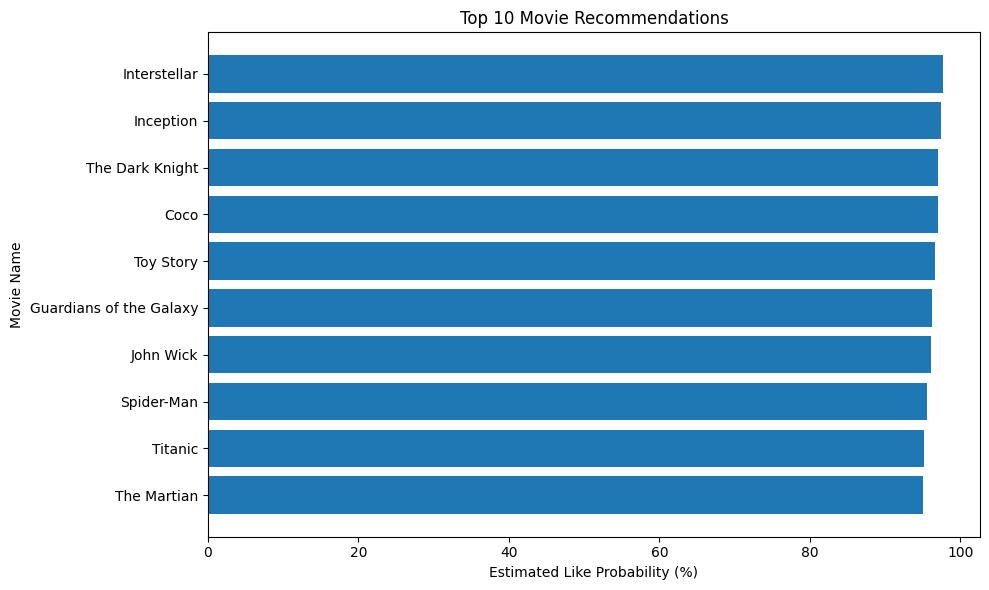

In [ ]:

# Step 9: Visualize Top Movie Recommendations

import matplotlib.pyplot as plt

top_movies = recommended_movies.head(10).sort_values(
    "Like_Probability"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_movies["Item"],
    top_movies["Like_Probability"] * 100
)

plt.xlabel("Estimated Like Probability (%)")
plt.ylabel("Movie Name")
plt.title("Top 10 Movie Recommendations")
plt.tight_layout()
plt.show()

In [ ]:

# Step 10: Export Recommendation Results

output_file = "movie_recommendation_results.csv"

recommended_movies.to_csv(output_file, index=False)

print("Recommendation results saved successfully!")

from google.colab import files
files.download(output_file)

Recommendation results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>